## **Importing needed libraries**
* ### Utitlies 
* ### Sklearn

In [7]:
#from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import pandas as pd
import numpy as np


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.utils import shuffle

#from imblearn.under_sampling import NearMiss
#from imblearn.under_sampling import NearMiss
#from imblearn.over_sampling import SMOTE, SMOTENC


In [3]:
pd.set_option('display.max_columns', 55)
plt.style.use('ggplot')

## **Reading PAMAP2 Data**

In [8]:
person1 = pd.read_csv('PAMAP2/Protocol/subject101.dat')
person2 = pd.read_csv('PAMAP2/Protocol/subject102.dat')
person3 = pd.read_csv('PAMAP2/Protocol/subject103.dat')
person4 = pd.read_csv('PAMAP2/Protocol/subject104.dat')
person5 = pd.read_csv('PAMAP2/Protocol/subject105.dat')
person6 = pd.read_csv('PAMAP2/Protocol/subject106.dat')
person7 = pd.read_csv('PAMAP2/Protocol/subject107.dat')
person8 = pd.read_csv('PAMAP2/Protocol/subject108.dat')

#### Starting off with Data manipulation
- putting the correct name for the feature
- changing the type of the feature from string to float
- storing the change in array of persons

In [ ]:
persons = [person1, person2, person3, person4,
           person5, person6, person7, person8]

for i in range(len(persons)):
    persons[i] = persons[i]['compressed'].str.split(' ', expand=True)
    persons[i].columns = ['timestamp', 'activityID', 'heart_rate', 'IMU_hand_temperature', 'IMU_hand_accx_scale16', 'IMU_hand_accy_scale16', 'IMU_hand_accz_scale16', 'IMU_hand_accx_scale6', 'IMU_hand_accy_scale6', 'IMU_hand_accz_scale6', 'IMU_hand_gyroscopex', 'IMU_hand_gyroscopey', 'IMU_hand_gyroscopez', 'IMU_hand_magnetometerx', 'IMU_hand_magnetometery', 'IMU_hand_magnetometerz', 'IMU_hand_orientation1', 'IMU_hand_orientation2', 'IMU_hand_orientation3', 'IMU_hand_orientation4', 'IMU_chest_temperature', 'IMU_chest_accx_scale16', 'IMU_chest_accy_scale16', 'IMU_chest_accz_scale16', 'IMU_chest_accx_scale6', 'IMU_chest_accy_scale6', 'IMU_chest_accz_scale6', 'IMU_chest_gyroscopex',
                          'IMU_chest_gyroscopey', 'IMU_chest_gyroscopez', 'IMU_chest_magnetometerx', 'IMU_chest_magnetometery', 'IMU_chest_magnetometerz', 'IMU_chest_orientation1', 'IMU_chest_orientation2', 'IMU_chest_orientation3', 'IMU_chest_orientation4', 'IMU_ankle_temperature', 'IMU_ankle_accx_scale16', 'IMU_ankle_accy_scale16', 'IMU_ankle_accz_scale16', 'IMU_ankle_accx_scale6', 'IMU_ankle_accy_scale6', 'IMU_ankle_accz_scale6', 'IMU_ankle_gyroscopex', 'IMU_ankle_gyroscopey', 'IMU_ankle_gyroscopez', 'IMU_ankle_magnetometerx', 'IMU_ankle_magnetometery', 'IMU_ankle_magnetometerz', 'IMU_ankle_orientation1', 'IMU_ankle_orientation2', 'IMU_ankle_orientation3', 'IMU_ankle_orientation4']
    # -------------------------------------------------------------

    for j in persons[i].columns:
        persons[i][j] = persons[i][j].astype(float)


#### adding column include subject number:
- to identify which record belonge to whom.

In [4]:
i = 0
for person in persons:
    i += 1
    person['person'] = pd.Series([f"{i}" for x in range(len(person.index))])


##### checking the data

In [52]:
persons[0].head()

,timestamp,activityID,heart_rate,IMU_hand_temperature,IMU_hand_accx_scale16,IMU_hand_accy_scale16,IMU_hand_accz_scale16,IMU_hand_accx_scale6,IMU_hand_accy_scale6,IMU_hand_accz_scale6,IMU_hand_gyroscopex,IMU_hand_gyroscopey,IMU_hand_gyroscopez,IMU_hand_magnetometerx,IMU_hand_magnetometery,IMU_hand_magnetometerz,IMU_hand_orientation1,IMU_hand_orientation2,IMU_hand_orientation3,IMU_hand_orientation4,IMU_chest_temperature,IMU_chest_accx_scale16,IMU_chest_accy_scale16,IMU_chest_accz_scale16,IMU_chest_accx_scale6,IMU_chest_accy_scale6,IMU_chest_accz_scale6,IMU_chest_gyroscopex,IMU_chest_gyroscopey,IMU_chest_gyroscopez,IMU_chest_magnetometerx,IMU_chest_magnetometery,IMU_chest_magnetometerz,IMU_chest_orientation1,IMU_chest_orientation2,IMU_chest_orientation3,IMU_chest_orientation4,IMU_ankle_temperature,IMU_ankle_accx_scale16,IMU_ankle_accy_scale16,IMU_ankle_accz_scale16,IMU_ankle_accx_scale6,IMU_ankle_accy_scale6,IMU_ankle_accz_scale6,IMU_ankle_gyroscopex,IMU_ankle_gyroscopey,IMU_ankle_gyroscopez,IMU_ankle_magnetometerx,IMU_ankle_magnetometery,IMU_ankle_magnetometerz,IMU_ankle_orientation1,IMU_ankle_orientation2,IMU_ankle_orientation3,IMU_ankle_orientation4,person
0,8.38,0.0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,-0.092217,0.056812,-0.015845,14.6806,-69.2128,-5.58905,1.0,0.0,0.0,0.0,31.8125,0.238080,9.80003,-1.68896,0.265304,9.81549,-1.41344,-0.005065,-0.006781,-0.005663,0.471960,-51.0499,43.2903,1.0,0.0,0.0,0.0,30.3125,9.65918,-1.655690,-0.099797,9.64689,-1.555760,0.310404,0.008300,0.009250,-0.017580,-61.1888,-38.9599,-58.1438,1.0,0.0,0.0,0.0,1
1,8.39,0.0,104.0,30.0,2.18837,8.56560,3.66179,2.39494,8.55081,3.64207,-0.024413,0.047759,0.006474,14.8991,-69.2224,-5.82311,1.0,0.0,0.0,0.0,31.8125,0.319530,9.61282,-1.49328,0.234939,9.78539,-1.42846,0.013685,0.001486,-0.041522,1.016900,-50.3966,43.1768,1.0,0.0,0.0,0.0,30.3125,9.69370,-1.579020,-0.215687,9.61670,-1.616300,0.280488,-0.006577,-0.004638,0.000368,-59.8479,-38.8919,-58.5253,1.0,0.0,0.0,0.0,1
2,8.40,0.0,104.0,30.0,2.37357,8.60107,3.54898,2.30514,8.53644,3.73280,-0.057976,0.032574,-0.006988,14.2420,-69.5197,-5.12442,1.0,0.0,0.0,0.0,31.8125,0.235593,9.72421,-1.76621,0.173850,9.72528,-1.51894,-0.039923,0.034056,-0.002113,0.383136,-51.8336,43.7782,1.0,0.0,0.0,0.0,30.3125,9.58944,-1.732760,0.092914,9.63173,-1.586050,0.280311,0.003014,0.000148,0.022495,-60.7361,-39.4138,-58.3999,1.0,0.0,0.0,0.0,1
3,8.41,0.0,104.0,30.0,2.07473,8.52853,3.66021,2.33528,8.53622,3.73277,-0.002352,0.032810,-0.003747,14.8908,-69.5439,-6.17367,1.0,0.0,0.0,0.0,31.8125,0.388697,9.53572,-1.72410,0.157969,9.64994,-1.57952,0.007513,-0.010498,-0.020684,0.315400,-49.8144,43.1670,1.0,0.0,0.0,0.0,30.3125,9.58814,-1.770400,0.054545,9.63197,-1.631350,0.340997,0.003175,-0.020301,0.011275,-60.4091,-38.7635,-58.3956,1.0,0.0,0.0,0.0,1
4,8.42,0.0,104.0,30.0,2.22936,8.83122,3.70000,2.23055,8.59741,3.76295,0.012269,0.018305,-0.053325,15.5612,-68.8196,-6.28927,1.0,0.0,0.0,0.0,31.8125,0.315800,9.49908,-1.60914,0.233506,9.57411,-1.44418,-0.003822,-0.011217,-0.025975,-0.297733,-51.8097,43.6453,1.0,0.0,0.0,0.0,30.3125,9.69771,-1.656250,-0.060809,9.64699,-1.646470,0.340965,0.012698,-0.014303,-0.002823,-61.5199,-39.3879,-58.2694,1.0,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376412,3772.50,0.0,128.0,30.5,2.02477,7.29553,5.74194,2.06573,6.57692,5.92695,1.516160,-0.044713,-0.085853,18.8018,-48.7508,-32.95910,1.0,0.0,0.0,0.0,34.0625,-0.414842,9.65041,-1.85519,-0.382686,9.71142,-1.50051,0.010358,0.001925,0.008888,12.621100,-39.1506,29.6394,1.0,0.0,0.0,0.0,33.3125,9.89247,-0.404788,-0.027988,9.82743,-0.315490,0.290320,0.048745,-0.008034,0.018600,-58.8381,-36.2397,-11.0980,1.0,0.0,0.0,0.0,1
376413,3772.51,0.0,128.0,30.5,2.10836,7.86504,5.85674,2.08754,7.42244,5.87977,1.542230,-0.023898,-0.075649,17.6871,-49.0142,-32.83350,1.0,0.0,0.

#### visual clarification for the null value 
- the heart rate sampling time is 9Hz while the IMU is 100Hz so there is alot of null value in the heart rate feature

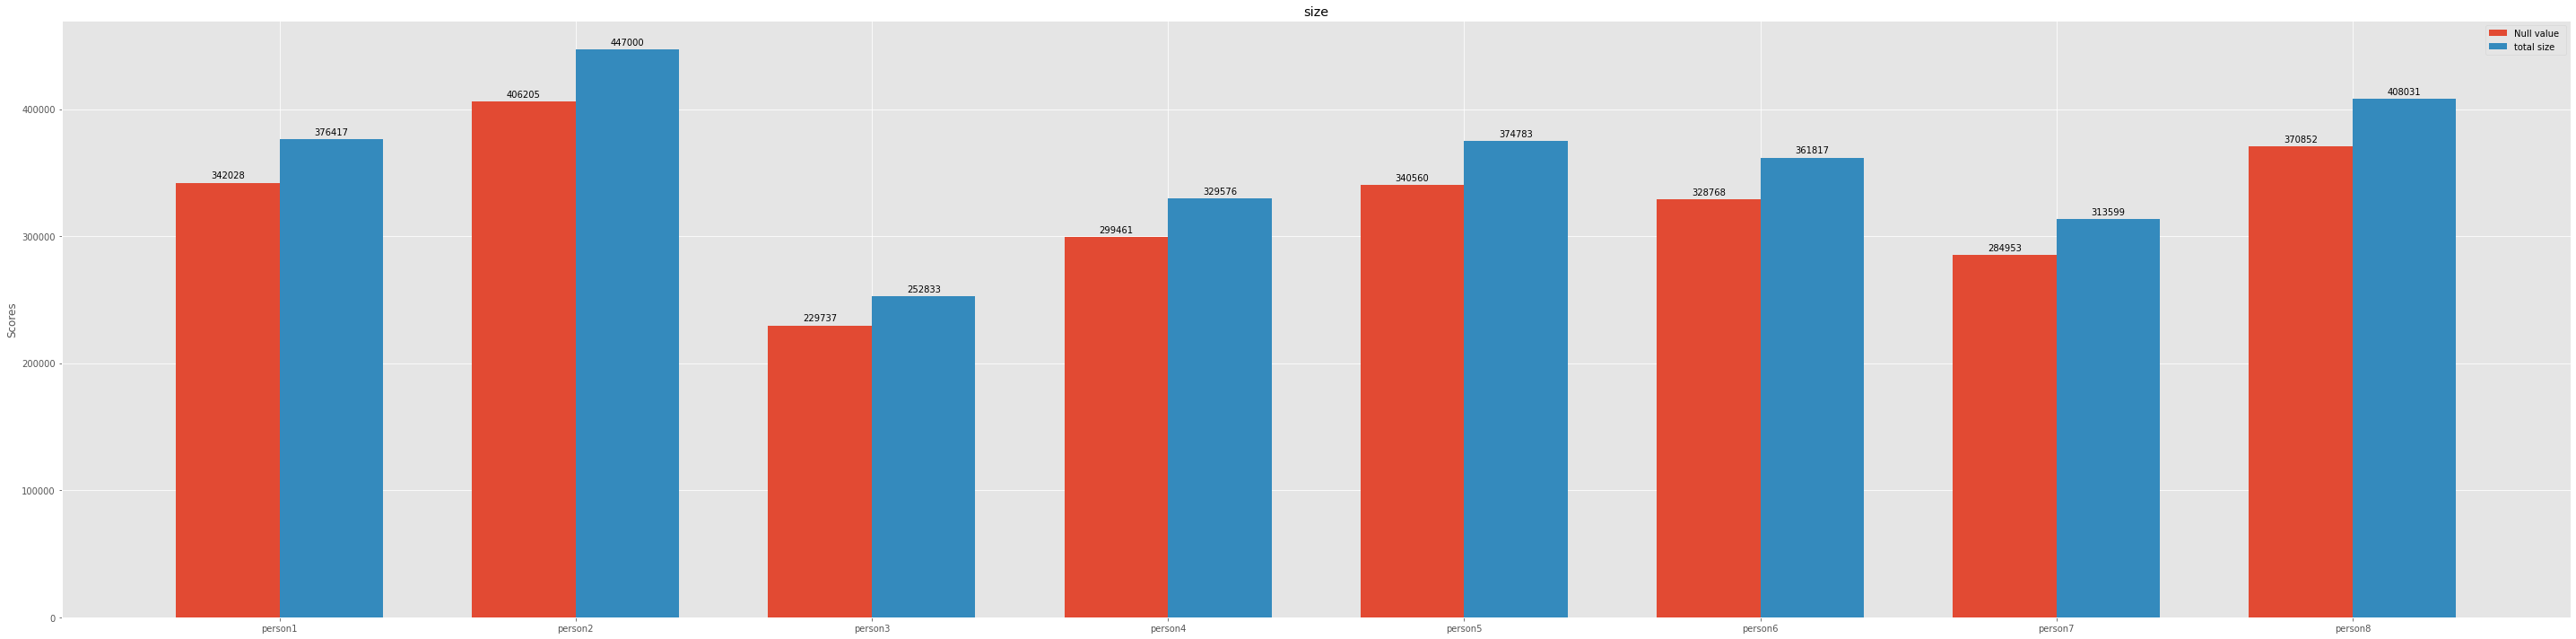

In [6]:
plt.rcParams["figure.figsize"] = (40, 10)


labels = ['person1', 'person2', 'person3', 'person4',
          'person5', 'person6', 'person7', 'person8']
null = []
total_size = []

for person in persons:
    null.append(person['heart_rate'].isna().sum())
    total_size.append(person.shape[0])


x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, null, width, label='Null value ')
rects2 = ax.bar(x + width/2, total_size, width, label='total size')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores')
ax.set_title('size')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()


#### another clarification for the heart rate null value

In [7]:
for i in range(len(persons)):
    print(f"number of null in person {i} record:  ",persons[i]['heart_rate'].isna().sum(),"      the total size :   ",persons[i].shape[0]
    ,'     the non null :',persons[i].shape[0]-persons[i]['heart_rate'].isna().sum())

number of null in person 0 record:   342028       the total size :    376417      the non null : 34389
number of null in person 1 record:   406205       the total size :    447000      the non null : 40795
number of null in person 2 record:   229737       the total size :    252833      the non null : 23096
number of null in person 3 record:   299461       the total size :    329576      the non null : 30115
number of null in person 4 record:   340560       the total size :    374783      the non null : 34223
number of null in person 5 record:   328768       the total size :    361817      the non null : 33049
number of null in person 6 record:   284953       the total size :    313599      the non null : 28646
number of null in person 7 record:   370852       the total size :    408031      the non null : 37179


### solving the heart rate null value problem:
- if we drop the rows which contain null vlaue there will be 90% loss of the data which is n't efficient 
- we thought to interpolate it with non linear polynomial but but that will be non logical 
- `the best solution for is to interpolate is with linear polynomial for every person`

In [8]:
for i in range(len(persons)):
    persons[i]['heart_rate'].interpolate(method ='linear', limit_direction ='both',inplace=True)

##### checking the data

In [9]:
persons[7]

,timestamp,activityID,heart_rate,IMU_hand_temperature,IMU_hand_accx_scale16,IMU_hand_accy_scale16,IMU_hand_accz_scale16,IMU_hand_accx_scale6,IMU_hand_accy_scale6,IMU_hand_accz_scale6,IMU_hand_gyroscopex,IMU_hand_gyroscopey,IMU_hand_gyroscopez,IMU_hand_magnetometerx,IMU_hand_magnetometery,IMU_hand_magnetometerz,IMU_hand_orientation1,IMU_hand_orientation2,IMU_hand_orientation3,IMU_hand_orientation4,IMU_chest_temperature,IMU_chest_accx_scale16,IMU_chest_accy_scale16,IMU_chest_accz_scale16,IMU_chest_accx_scale6,IMU_chest_accy_scale6,IMU_chest_accz_scale6,IMU_chest_gyroscopex,IMU_chest_gyroscopey,IMU_chest_gyroscopez,IMU_chest_magnetometerx,IMU_chest_magnetometery,IMU_chest_magnetometerz,IMU_chest_orientation1,IMU_chest_orientation2,IMU_chest_orientation3,IMU_chest_orientation4,IMU_ankle_temperature,IMU_ankle_accx_scale16,IMU_ankle_accy_scale16,IMU_ankle_accz_scale16,IMU_ankle_accx_scale6,IMU_ankle_accy_scale6,IMU_ankle_accz_scale6,IMU_ankle_gyroscopex,IMU_ankle_gyroscopey,IMU_ankle_gyroscopez,IMU_ankle_magnetometerx,IMU_ankle_magnetometery,IMU_ankle_magnetometerz,IMU_ankle_orientation1,IMU_ankle_orientation2,IMU_ankle_orientation3,IMU_ankle_orientation4,person
0,5.89,0.0,78.0,33.3125,-9.79760,-1.45670,1.014380,-9.70702,-1.60337,1.320980,0.030436,-0.015329,0.048605,49.1280,-8.80286,12.1940,1.000000,0.000000,0.000000,0.000000,36.0625,0.364336,9.69823,0.017375,0.110468,9.81336,0.370771,0.092914,-0.061808,0.041628,7.540770,-39.8524,26.3559,1.000000,0.000000,0.000000,0.000000,32.8125,9.59377,-0.039484,-2.69600,9.57575,-0.122278,-2.44844,-0.013731,0.010364,0.010731,-35.4550,38.3829,-17.9083,0.546211,0.370903,0.695334,0.283892,8
1,5.90,0.0,78.0,33.3125,-9.91204,-1.41822,0.974050,-9.78262,-1.60285,1.290850,-0.011127,-0.013590,0.047283,48.8748,-8.54106,12.3241,1.000000,0.000000,0.000000,0.000000,36.0625,0.250491,9.88686,0.014699,0.110642,9.79821,0.416064,0.077161,-0.020504,0.061780,6.244750,-39.2887,26.3437,1.000000,0.000000,0.000000,0.000000,32.8125,9.66662,-0.001347,-2.77267,9.56080,-0.076888,-2.43337,0.004436,-0.005926,-0.006704,-35.4508,38.2543,-17.7663,0.545806,0.370867,0.695680,0.283872,8
2,5.91,0.0,78.0,33.3125,-9.87531,-1.57027,0.975113,-9.78237,-1.57265,1.290790,-0.030363,-0.027122,0.024034,48.7542,-8.41097,11.6674,1.000000,0.000000,0.000000,0.000000,36.0625,0.095745,9.88682,-0.065546,0.050393,9.81348,0.386246,0.079766,-0.043622,0.068805,7.648350,-38.3086,26.2069,0.573907,-0.553910,-0.416557,-0.436227,32.8125,9.48180,-0.190968,-2.65762,9.57594,-0.091972,-2.40313,0.022508,-0.002265,0.014646,-35.6984,38.2688,-17.0580,0.545484,0.371607,0.695437,0.284117,8
3,5.92,0.0,78.0,33.3125,-9.72175,-1.60870,1.054520,-9.70677,-1.60334,1.351180,-0.008672,-0.025197,0.019366,49.0030,-8.42425,11.6670,1.000000,0.000000,0.000000,0.000000,36.0625,0.067625,9.77631,0.282792,0.035999,9.85871,0.446915,0.075553,-0.020911,0.044181,7.268160,-38.5523,26.0646,0.572119,-0.549803,-0.419715,-0.440722,32.8125,9.66563,-0.191190,-2.77150,9.62108,-0.076819,-2.38829,-0.006964,0.035314,0.010982,-34.9492,38.7447,-17.6233,0.545474,0.372077,0.694859,0.284935,8
4,5.93,0.0,78.0,33.3125,-9.79920,-1.49497,0.975999,-9.58657,-1.57408,1.275490,0.011593,-0.069777,-0.002699,48.7537,-8.53486,11.9306,1.000000,0.000000,0.000000,0.000000,36.0625,-0.082645,9.73965,0.357631,-0.068852,9.82861,0.553249,0.088234,-0.020777,0.039643,7.406800,-39.2023,26.0693,0.573024,-0.545930,-0.422149,-0.442033,32.8125,9.59518,-0.192001,-2.61786,9.62158,-0.091796,-2.26716,-0.015835,-0.001065,-0.000410,-35.2105,38.8857,-17.9080,0.545810,0.372349,0.694122,0.285732,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
408026,4086.15,0.0,140.0,30.8125,-9.54108,-2.02884,0.904692,-9.54984,-2.19390,0.884190,-0.027300,0.049635,-0.014393,43.7216,12.92550,-30.5773,0.032533,0.670927,0.111851,-0.732317,34.2500,-0.937180,9.73864,-0.199940,-1.097480,9.

### splittng the data (in the next 2 blocks)
- we want the data to be n't bais to `specific person` or to `specific activity `
##### to solve the problem and to make the data to generlize for the population:
- first we splitted the train and test sample for every person independently and concatenate it so `every person has the same ratio in the training and testing data`.
- second n't only we splitted it for every person but also for every activity we splitted the train and test sample for it independently and concatenate it so `every activity  has the same ratio in the training and testing data`.

- we concatonate all that in datasets_train and datasets_test

In [10]:
lying_train=[]
sitting_train=[]
walking_train=[]
running_train=[]

lying_test=[]
sitting_test=[]
walking_test=[]
running_test=[]


datasets=persons[0]

filers=(datasets['activityID']==1) 
dataset0=datasets[filers]

#-------------------------------------------------------------
print("class ",1 ,dataset0.shape[0])
#-------------------------------------------------------------
datasets_train,datasets_test=train_test_split(dataset0,random_state=70)
#-------------------------------------------------------------
lying_train.append(datasets_train.shape[0]) # to visualize it later
lying_test.append(datasets_test.shape[0]) # to visualize it later

for i in [2,4,5]:
       

        filers=(datasets['activityID']==i) 
        dataset=datasets[filers]

        #-------------------------------------------------------------
        print("class ",i ,dataset.shape[0],)
        #-------------------------------------------------------------
        dataset_train,dataset_test=train_test_split(dataset,random_state=70)
        #-------------------------------------------------------------
       
        if i==2:
              sitting_train.append(dataset_train.shape[0]) 
              sitting_test.append(dataset_test.shape[0]) 
        elif i==4:
              walking_train.append(dataset_train.shape[0])
              walking_test.append(dataset_test.shape[0])
        else:
              running_train.append(dataset_train.shape[0]) 
              running_test.append(dataset_test.shape[0])
        #-------------------------------------------------------------
        datasets_train=pd.concat([datasets_train,dataset_train],ignore_index=True)
        datasets_test=pd.concat([datasets_test,dataset_test],ignore_index=True)



class  1 27187
class  2 23480
class  4 22253
class  5 21265


In [11]:
person=2
total_record=datasets_train.shape[0]+datasets_test.shape[0]
for i in range(1,8,1):
    dataset=persons[i]
    #-------------------------------------------------------------
    for i in [1,2,4,5]:

            filers=(dataset['activityID']==i) 
            dataset1=dataset[filers]

            #-------------------------------------------------------------
            total_record+=dataset1.shape[0]
            print('person: ',person,"  class: ",i ,'  size: ',dataset1.shape[0])
            #-------------------------------------------------------------
            if dataset1.shape[0]>1:
                dataset_train,dataset_test=train_test_split(dataset1,random_state=70)
            if i==1:
                lying_train.append(dataset_train.shape[0]) # to visualize it later
                lying_test.append(dataset_test.shape[0])
            elif i==2:
                sitting_train.append(dataset_train.shape[0]) 
                sitting_test.append(dataset_test.shape[0]) 
            elif i==4:
                walking_train.append(dataset_train.shape[0])
                walking_test.append(dataset_test.shape[0])
            else:
                running_train.append(dataset_train.shape[0]) 
                running_test.append(dataset_test.shape[0])
                #-------------------------------------------------------------
                
            datasets_train=pd.concat([datasets_train,dataset_train],ignore_index=True)
            datasets_test=pd.concat([datasets_test,dataset_test],ignore_index=True)
            
            datasets_train=shuffle(datasets_train,random_state=100)
            datasets_test=shuffle(datasets_test,random_state=100)
    
    person+=1
#-------------------------------------------------------------

print('total_record:',total_record)


person:  2   class:  1   size:  23430
person:  2   class:  2   size:  22345
person:  2   class:  4   size:  32533
person:  2   class:  5   size:  9238
person:  3   class:  1   size:  22044
person:  3   class:  2   size:  28761
person:  3   class:  4   size:  29036
person:  3   class:  5   size:  0
person:  4   class:  1   size:  23047
person:  4   class:  2   size:  25492
person:  4   class:  4   size:  31932
person:  4   class:  5   size:  1
person:  5   class:  1   size:  23699
person:  5   class:  2   size:  26864
person:  5   class:  4   size:  32033
person:  5   class:  5   size:  24646
person:  6   class:  1   size:  23340
person:  6   class:  2   size:  23041
person:  6   class:  4   size:  25721
person:  6   class:  5   size:  22825
person:  7   class:  1   size:  25611
person:  7   class:  2   size:  12282
person:  7   class:  4   size:  33720
person:  7   class:  5   size:  3692
person:  8   class:  1   size:  24165
person:  8   class:  2   size:  22923
person:  8   class:  4

### in the below 2 blocks we visualize the ratio of every person activity in the training and testing data compare to each other

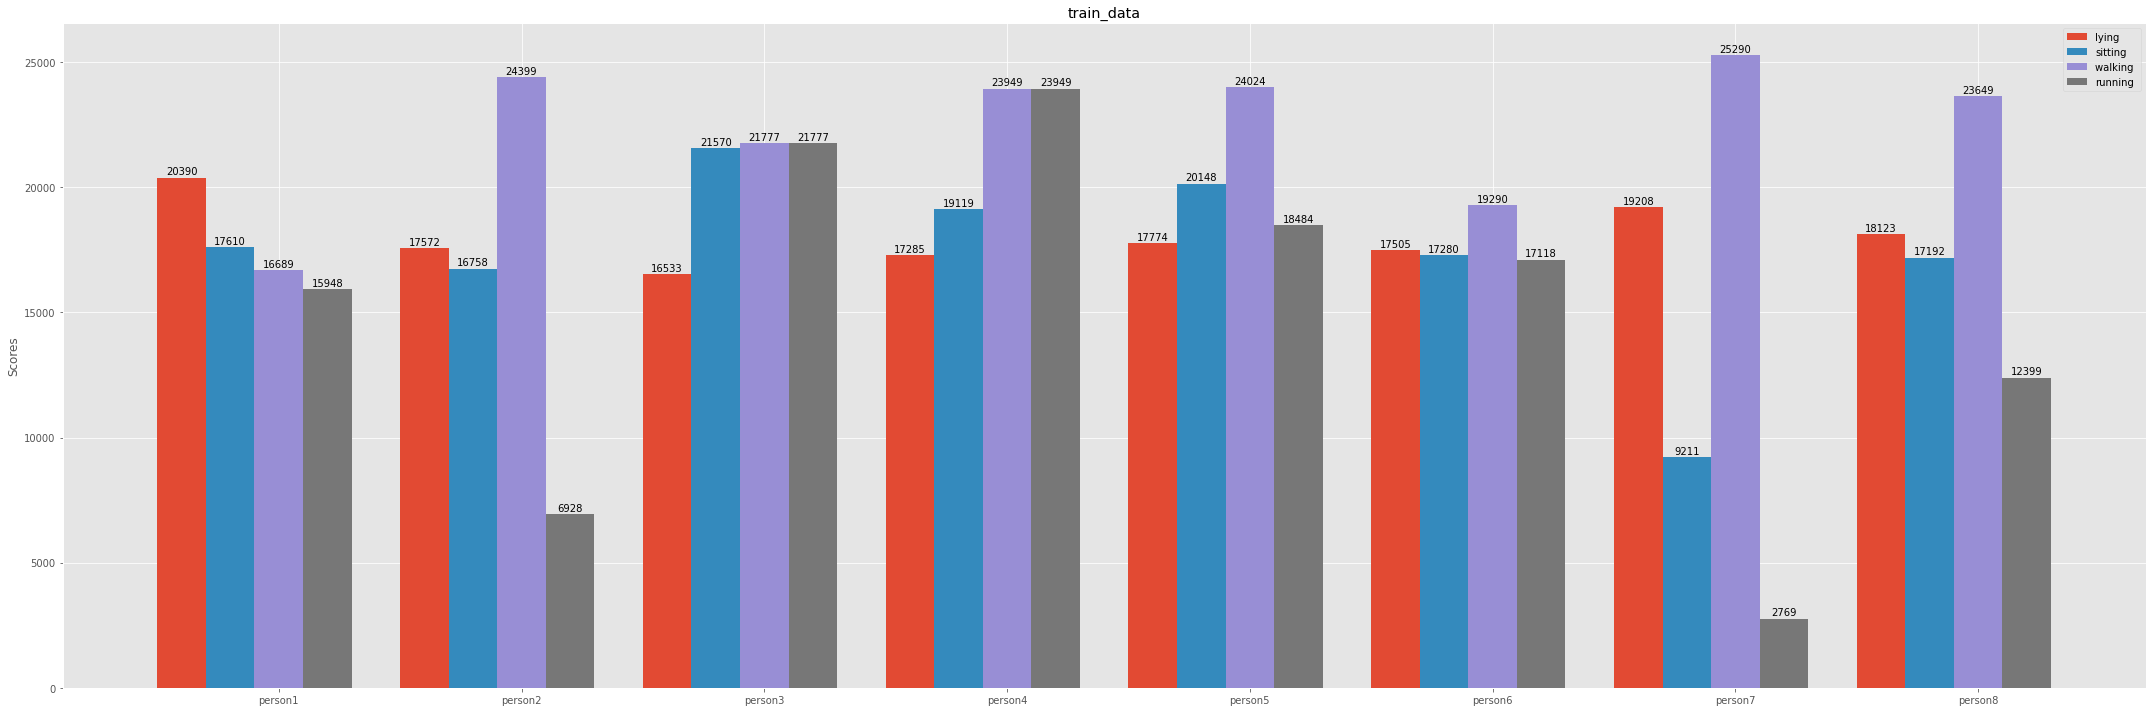

In [12]:
plt.rcParams["figure.figsize"] = (30,10)


labels = ['person1', 'person2', 'person3', 'person4','person5', 'person6', 'person7', 'person8']


x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - 2*width, lying_train, width, label='lying')
rects2 = ax.bar(x - width, sitting_train, width, label='sitting')
rects3 = ax.bar(x , walking_train, width, label='walking ')
rects4 = ax.bar(x + width, running_train, width, label='running')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores')
ax.set_title('train_data')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=1)
ax.bar_label(rects2, padding=1)
ax.bar_label(rects3, padding=1)
ax.bar_label(rects4, padding=1)
fig.tight_layout()

plt.show()

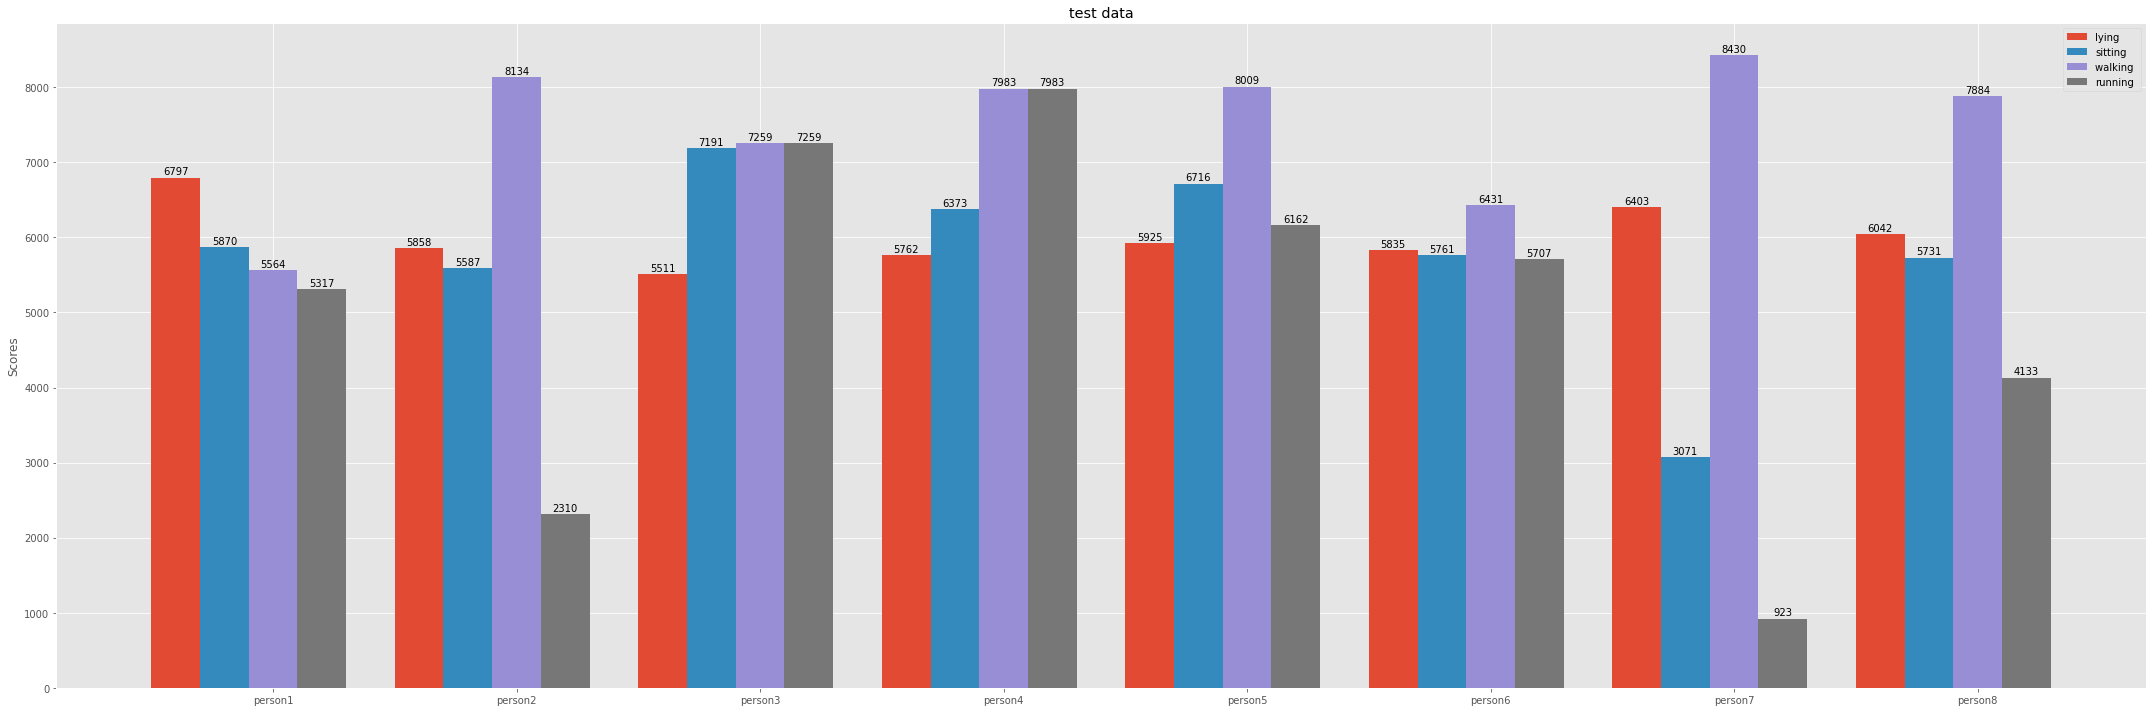

In [13]:
plt.rcParams["figure.figsize"] = (30,10)


labels = ['person1', 'person2', 'person3', 'person4','person5', 'person6', 'person7', 'person8']


x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - 2*width, lying_test, width, label='lying')
rects2 = ax.bar(x - width, sitting_test, width, label='sitting')
rects3 = ax.bar(x , walking_test, width, label='walking ')
rects4 = ax.bar(x + width, running_test, width, label='running')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores')
ax.set_title('test data')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=1)
ax.bar_label(rects2, padding=1)
ax.bar_label(rects3, padding=1)
ax.bar_label(rects4, padding=1)
fig.tight_layout()

plt.show()

### in the below 2 blocks we visualize the ratio of every activity in the training and testing data for all the persons

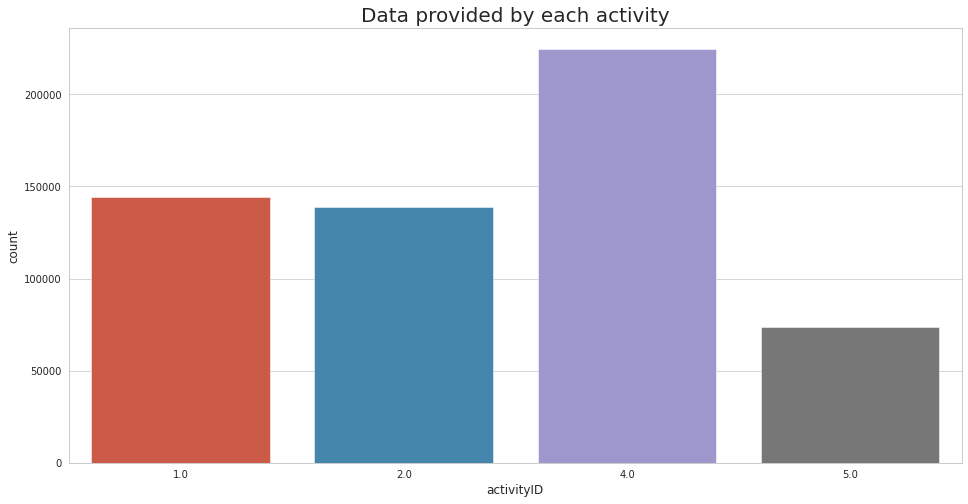

In [14]:
sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'Dejavu Sans'
plt.figure(figsize=(16,8))
plt.title('Data provided by each activity', fontsize=20)
sns.countplot(x='activityID', data = datasets_train)
plt.show()

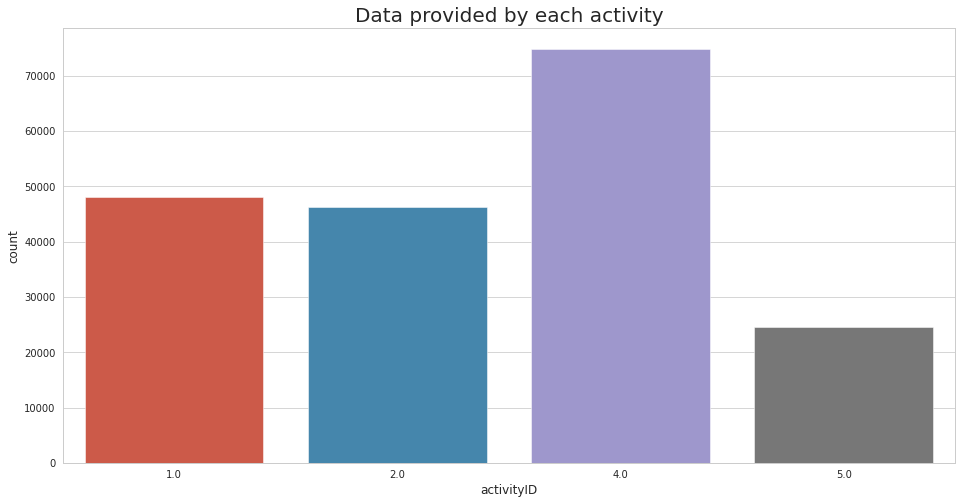

In [15]:
sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'Dejavu Sans'
plt.figure(figsize=(16,8))
plt.title('Data provided by each activity', fontsize=20)
sns.countplot(x='activityID', data = datasets_test)
plt.show()

#### we see here if there is any left null value in any feature:

<AxesSubplot:>

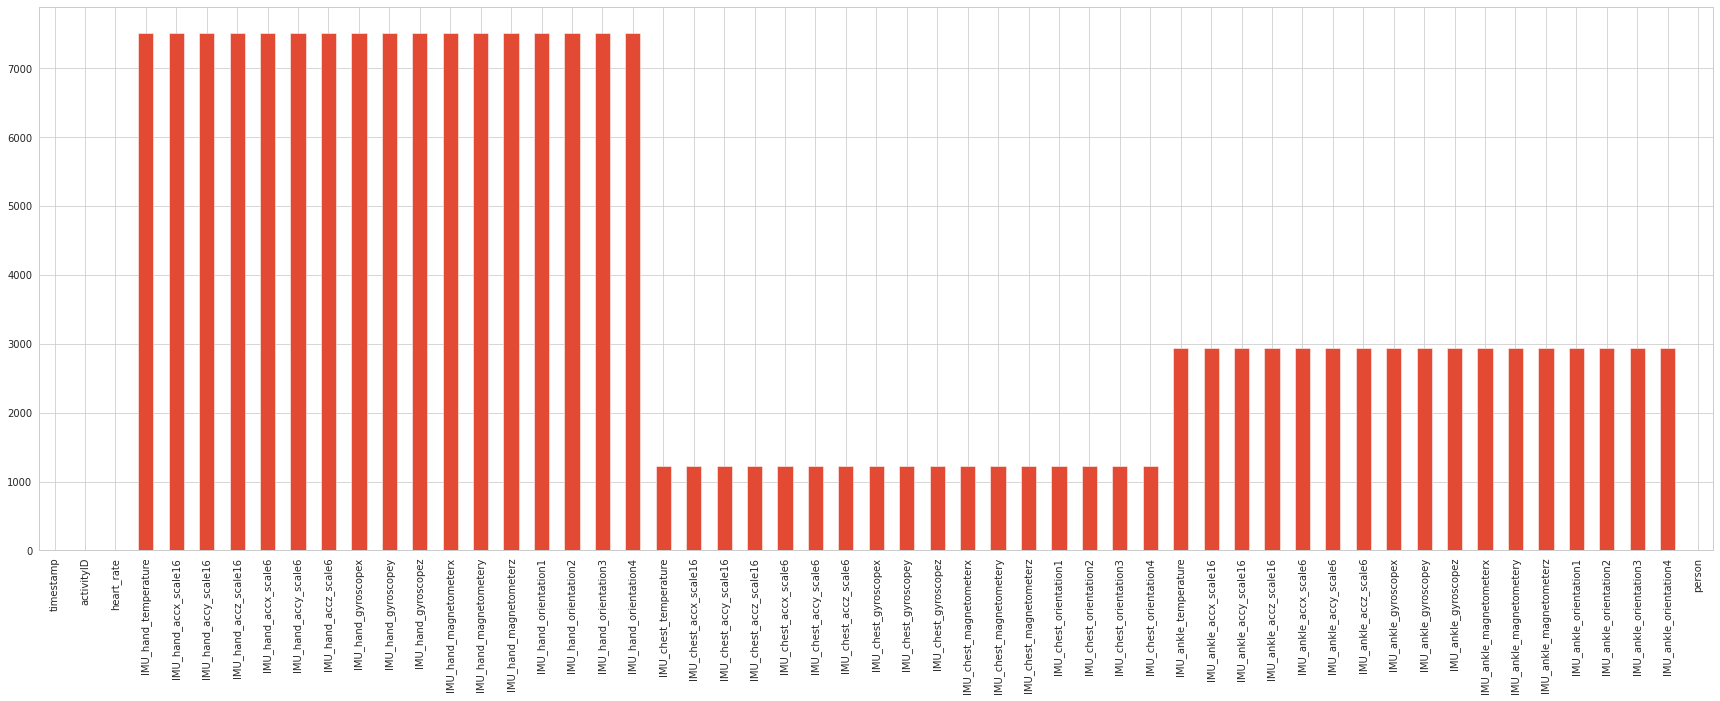

In [16]:
datasets_train.isna().sum().plot.bar()

#### from the above graph the null data feature is too small so it willn't affect if we drop it

In [17]:
for data in [datasets_train,datasets_test]:
    data.dropna(axis='rows',inplace=True)
    data.dropna(axis='rows',inplace=True)

##### IMU_orientation feature
- don't add anything to the data as it always 0 `so we drop it`


<AxesSubplot:>

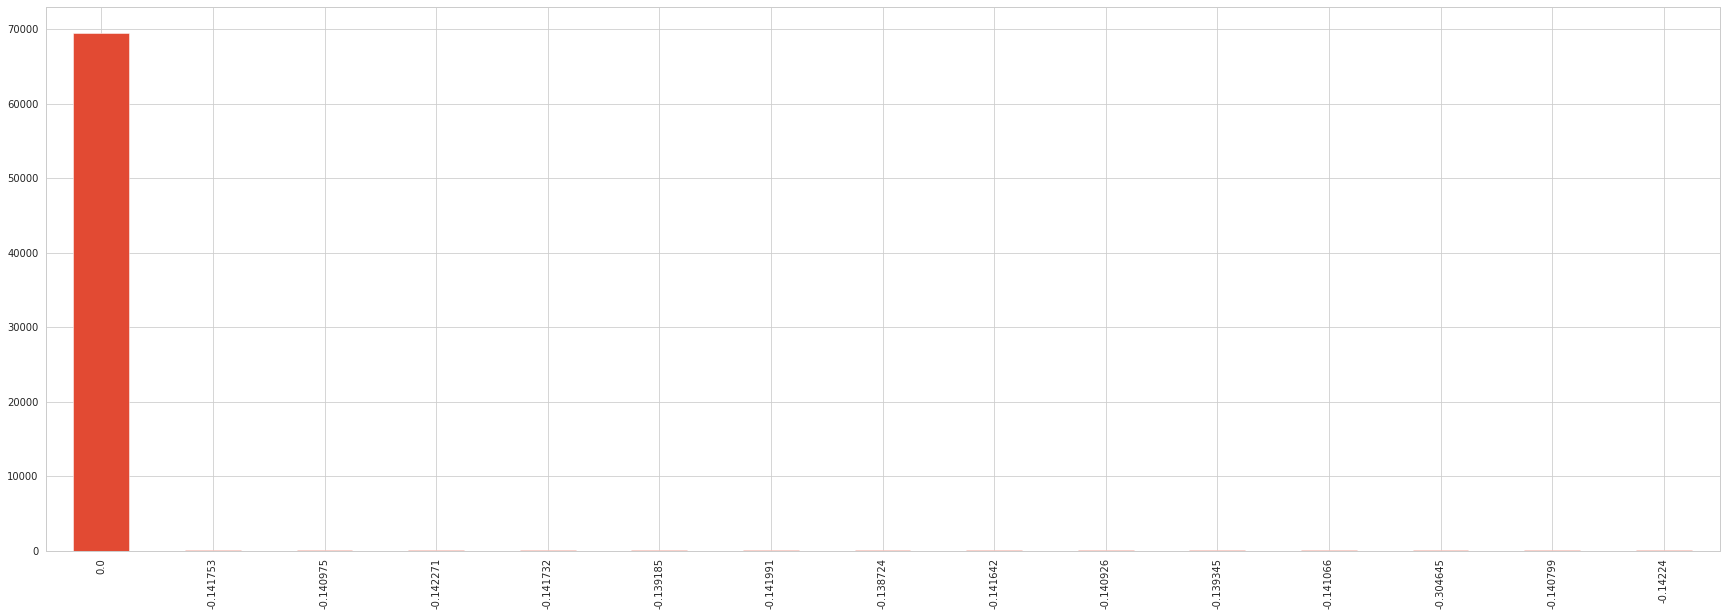

In [18]:
datasets_train['IMU_hand_orientation2'].value_counts().iloc[:15].plot.bar()

In [19]:
datasets_train['IMU_chest_orientation4'].value_counts()

 0.000000    69514
 0.173511       15
 0.173351       14
 0.150790       14
 0.174483       14
             ...  
 0.023186        1
-0.004412        1
 0.090770        1
 0.479460        1
 0.012058        1
Name: IMU_chest_orientation4, Length: 346920, dtype: int64

In [20]:
for data in [datasets_train, datasets_test]:
    data.drop('IMU_hand_orientation1', inplace=True, axis=1)
    data.drop('IMU_hand_orientation2', inplace=True, axis=1)
    data.drop('IMU_hand_orientation3', inplace=True, axis=1)
    data.drop('IMU_hand_orientation4', inplace=True, axis=1)

    data.drop('IMU_chest_orientation1', inplace=True, axis=1)
    data.drop('IMU_chest_orientation2', inplace=True, axis=1)
    data.drop('IMU_chest_orientation3', inplace=True, axis=1)
    data.drop('IMU_chest_orientation4', inplace=True, axis=1)

    data.drop('IMU_ankle_orientation1', inplace=True, axis=1)
    data.drop('IMU_ankle_orientation2', inplace=True, axis=1)
    data.drop('IMU_ankle_orientation3', inplace=True, axis=1)
    data.drop('IMU_ankle_orientation4', inplace=True, axis=1)

    data.drop('timestamp', inplace=True, axis=1)


### we shuffle all the data to randomize it for all the people :
- so the data will n't be bais to one person

In [21]:
for i in range(200):

    datasets_train=shuffle(datasets_train,random_state=100)
    datasets_test=shuffle(datasets_test,random_state=100)

    
#-------------------------------------------------------------
datasets_train= datasets_train[[c for c in datasets_train if c not in ['activityID']] + ['activityID']]
datasets_test= datasets_test[[c for c in datasets_test if c not in ['activityID']] + ['activityID']]

In [22]:
datasets_train

,heart_rate,IMU_hand_temperature,IMU_hand_accx_scale16,IMU_hand_accy_scale16,IMU_hand_accz_scale16,IMU_hand_accx_scale6,IMU_hand_accy_scale6,IMU_hand_accz_scale6,IMU_hand_gyroscopex,IMU_hand_gyroscopey,IMU_hand_gyroscopez,IMU_hand_magnetometerx,IMU_hand_magnetometery,IMU_hand_magnetometerz,IMU_chest_temperature,IMU_chest_accx_scale16,IMU_chest_accy_scale16,IMU_chest_accz_scale16,IMU_chest_accx_scale6,IMU_chest_accy_scale6,IMU_chest_accz_scale6,IMU_chest_gyroscopex,IMU_chest_gyroscopey,IMU_chest_gyroscopez,IMU_chest_magnetometerx,IMU_chest_magnetometery,IMU_chest_magnetometerz,IMU_ankle_temperature,IMU_ankle_accx_scale16,IMU_ankle_accy_scale16,IMU_ankle_accz_scale16,IMU_ankle_accx_scale6,IMU_ankle_accy_scale6,IMU_ankle_accz_scale6,IMU_ankle_gyroscopex,IMU_ankle_gyroscopey,IMU_ankle_gyroscopez,IMU_ankle_magnetometerx,IMU_ankle_magnetometery,IMU_ankle_magnetometerz,person,activityID
10032,113.0,34.6250,-8.058770,0.869532,3.842160,-8.977290,1.26387,4.605920,1.558130,0.189324,-2.006310,40.06190,-29.3094,-14.56590,38.2500,1.165080,7.66375,0.232099,1.031330,7.985060,0.344790,-0.174478,0.055935,0.412273,-9.838300,-38.26550,-14.24230,34.1875,1.801970,-1.606540,-0.103500,1.370100,-1.890180,0.461387,-0.067253,-0.060013,3.130160,-34.4257,-14.04720,32.64840,5,4.0
300620,78.0,34.3750,-2.006210,-9.412110,0.773054,-1.816420,-9.43815,1.179060,-0.047402,-0.013969,-0.003339,7.90150,23.6593,-14.55950,37.6250,0.145695,10.03990,0.322071,-0.051508,10.190800,0.554196,-0.022176,-0.006648,-0.012781,6.527090,-25.21010,-3.76820,34.0000,9.074550,2.776400,-3.066100,9.050120,2.902390,-2.621870,-0.008223,0.026004,-0.025344,-18.7112,16.81560,24.29980,8,2.0
509722,78.0,33.9375,-5.651540,5.119040,5.942200,-5.418730,5.12109,6.330420,-0.003518,0.022949,-0.056724,12.77780,-23.1937,-21.50470,37.3750,0.141681,9.37301,-3.625370,0.130233,9.411110,-3.454000,-0.142220,0.014008,0.039144,-0.326429,-21.74100,6.05402,34.7500,9.464610,-2.440190,-1.524740,9.445700,-2.419590,-1.047920,-0.005339,-0.044621,-0.010244,-14.4263,-4.47298,21.43140,2,2.0
509174,87.0,31.1250,0.501824,5.809000,7.879440,0.418576,5.76016,8.044530,-0.014975,0.004657,-0.015684,-32.03810,16.8466,-38.96080,32.9375,0.775453,2.04204,9.497620,0.838500,2.071290,9.607910,0.002165,0.026829,-0.004830,38.878000,10.12880,-53.98420,31.5625,-0.516392,-7.498430,-6.805300,-0.598147,-7.434850,-6.457390,0.032108,0.032219,0.004754,-14.7774,44.77420,-6.01446,1,1.0
188904,72.0,31.9375,1.118750,9.214710,3.181730,1.192230,9.16334,3.385250,-0.005373,0.009388,-0.002036,-1.70449,-20.8041,-15.06380,34.9375,0.407677,9.37813,2.807110,0.350496,9.371130,3.254540,-0.013145,-0.018067,-0.014508,4.871670,-18.66300,-7.34652,32.8750,9.735310,0.272122,0.892349,9.726510,0.441923,1.257070,0.033007,0.007744,-0.000987,-13.7824,-3.90997,18.83280,3,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532723,60.0,31.0625,0.439910,4.525350,8.537130,0.459279,4.52214,8.756940,0.003733,0.020271,-0.007415,-5.39229,16.6622,-33.25630,33.8750,0.617675,2.19183,9.300670,0.553139,2.238100,9.504330,0.009201,0.014812,-0.016041,35.012000,4.20531,-32.78390,30.8125,-0.842473,-8.612890,-4.910830,-1.072310,-8.567310,-4.801490,0.006142,0.018638,0.014799,-11.6695,29.63340,-6.75157,7,1.0
284493,175.0,28.0625,-6.176950,7.754340,-1.040780,-7.489540,11.27620,-0.627304,-3.162410,4.442160,5.492780,4.65820,-57.3475,-44.77000,33.1875,3.990110,21.02630,-4.677710,6.122210,23.103500,-4.523400,-0.909302,3.727620,-0.633595,29.010900,-63.18930,3.23108,33.8125,30.053300,2.491560,1.820140,30.364200,3.883170,3.906130,0.149327,0.317271,-1.485820,-50.4585,-9.87250,-1.59441,6,5.0
126182,170.0,28.1875,11.566200,-4.430710,1.190480,11.509700,-5.26065,0.899569,1.965310,-3.286890,-0.097749,13.85420,-44.2858,-6.54803,33.2500,1.867140,-1.56307,0.352251,1.202040,-0.981036,0.665310,-0.680450,-0.617680,0.665457,-8.176420,-39.75590,-4.35194,33.8750,22.644000,8.671130,-0.686745,15

### from the below scatter matrix we deduce that:
- heart rate is seperating the data well

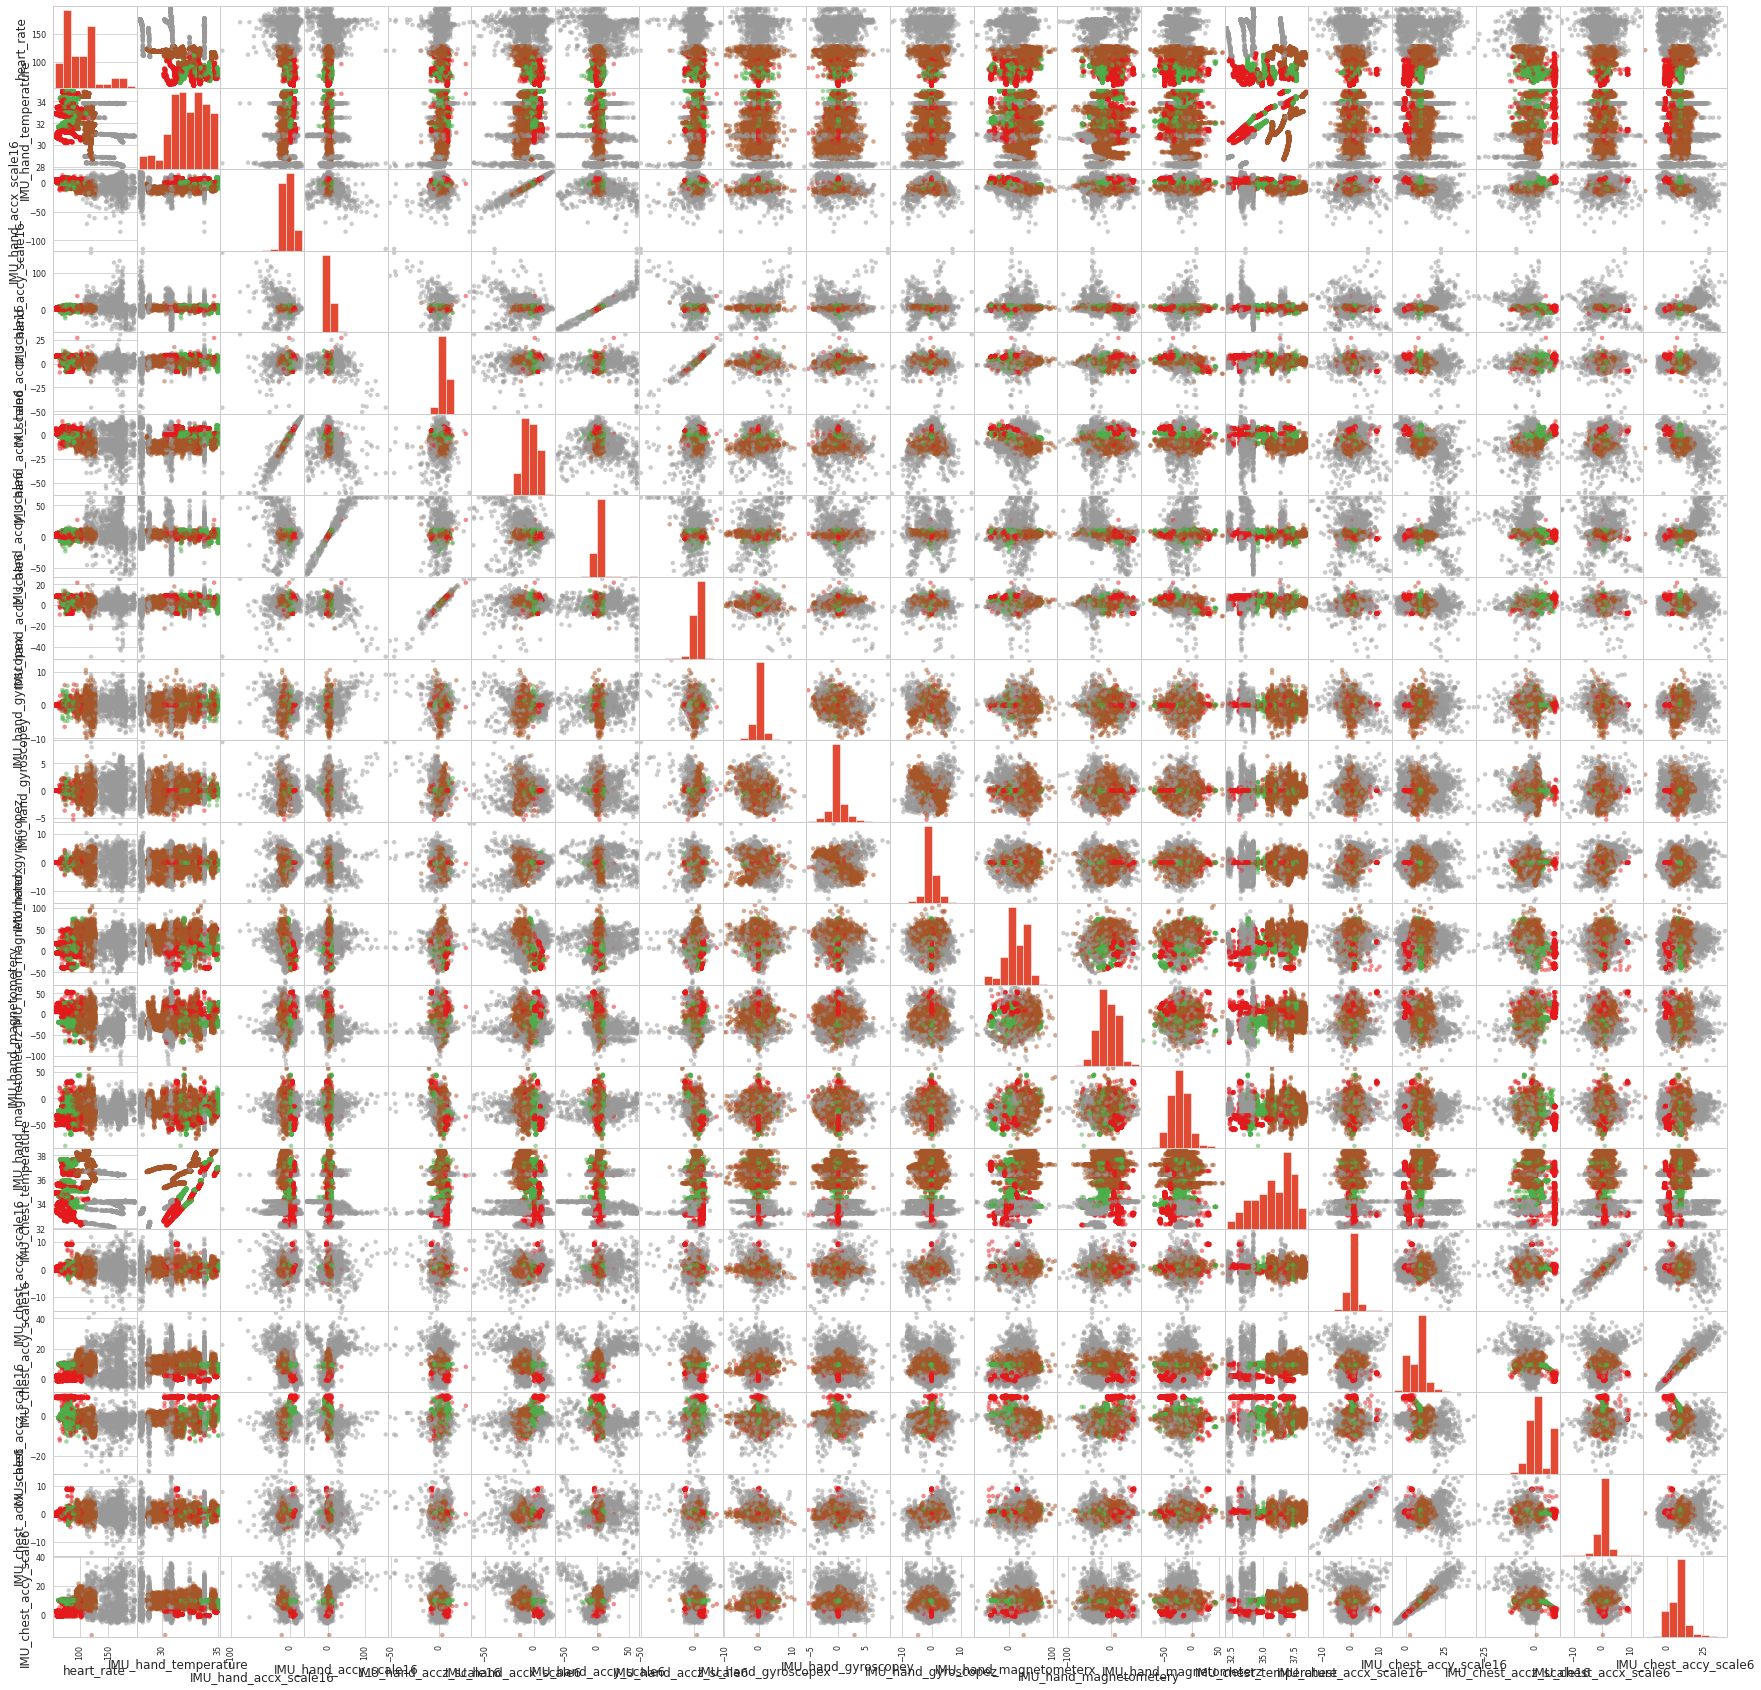

In [23]:
cmap=cm.get_cmap('Set1')
y=datasets_train.iloc[:10000,-1]
x=datasets_train.iloc[:10000,:-2]
# print(x.shape,y.shape)
scatter=pd.plotting.scatter_matrix( x.iloc[:,0:20], c=y ,marker='o',s=20,figsize=(30,30),cmap=cmap)



### deduction from the below heatmap:
- we see that the correlation between `IMU_acc_scale16` is almost 1 with `IMU_acc_scale6`.
- from the `activity id` column we deduce that the best feature is heart rate.
- we see that the correlation between `IMU_chest_magnetometery` is almost 0.7 with `IMU_chest_magnetometerx` and `IMU_chest_accz_scale16`.


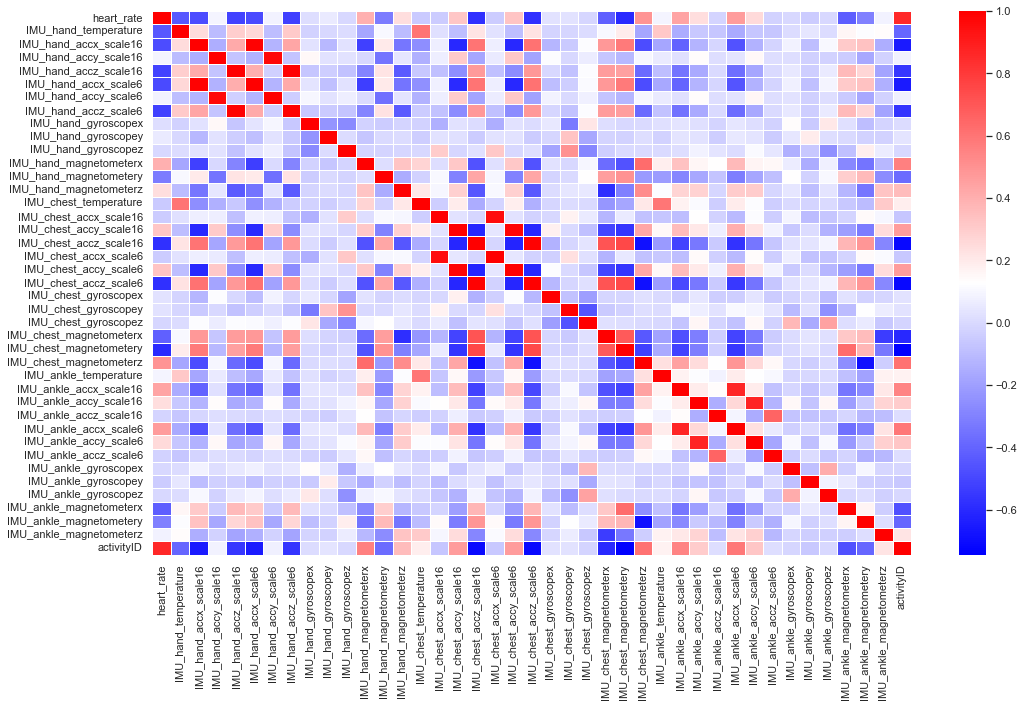

In [24]:
corr = datasets_train.corr()
# the heat map of the corrlations Better visualization
sns.set(rc={'figure.figsize': (17, 10)})
dataplot = sns.heatmap(corr, cmap="bwr", linewidths=.5)

#### so we drop all the the feature which will n't add more info for the model

In [25]:


for data in [datasets_train,datasets_test]:
    data.drop('IMU_hand_accx_scale6', inplace=True, axis=1)
    data.drop('IMU_hand_accy_scale6', inplace=True, axis=1)
    data.drop('IMU_hand_accz_scale6', inplace=True, axis=1)

    data.drop('IMU_chest_accx_scale6', inplace=True, axis=1)
    data.drop('IMU_chest_accy_scale6', inplace=True, axis=1)
    data.drop('IMU_chest_accz_scale6', inplace=True, axis=1)
    
    data.drop('IMU_ankle_accx_scale6', inplace=True, axis=1)
    data.drop('IMU_ankle_accy_scale6', inplace=True, axis=1)
    data.drop('IMU_ankle_accz_scale6', inplace=True, axis=1)

    data.drop('IMU_chest_magnetometerx', inplace=True, axis=1)
    data.drop('IMU_chest_magnetometery', inplace=True, axis=1)


In [26]:
datasets_train

,heart_rate,IMU_hand_temperature,IMU_hand_accx_scale16,IMU_hand_accy_scale16,IMU_hand_accz_scale16,IMU_hand_gyroscopex,IMU_hand_gyroscopey,IMU_hand_gyroscopez,IMU_hand_magnetometerx,IMU_hand_magnetometery,IMU_hand_magnetometerz,IMU_chest_temperature,IMU_chest_accx_scale16,IMU_chest_accy_scale16,IMU_chest_accz_scale16,IMU_chest_gyroscopex,IMU_chest_gyroscopey,IMU_chest_gyroscopez,IMU_chest_magnetometerz,IMU_ankle_temperature,IMU_ankle_accx_scale16,IMU_ankle_accy_scale16,IMU_ankle_accz_scale16,IMU_ankle_gyroscopex,IMU_ankle_gyroscopey,IMU_ankle_gyroscopez,IMU_ankle_magnetometerx,IMU_ankle_magnetometery,IMU_ankle_magnetometerz,person,activityID
10032,113.0,34.6250,-8.058770,0.869532,3.842160,1.558130,0.189324,-2.006310,40.06190,-29.3094,-14.56590,38.2500,1.165080,7.66375,0.232099,-0.174478,0.055935,0.412273,-14.24230,34.1875,1.801970,-1.606540,-0.103500,-0.067253,-0.060013,3.130160,-34.4257,-14.04720,32.64840,5,4.0
300620,78.0,34.3750,-2.006210,-9.412110,0.773054,-0.047402,-0.013969,-0.003339,7.90150,23.6593,-14.55950,37.6250,0.145695,10.03990,0.322071,-0.022176,-0.006648,-0.012781,-3.76820,34.0000,9.074550,2.776400,-3.066100,-0.008223,0.026004,-0.025344,-18.7112,16.81560,24.29980,8,2.0
509722,78.0,33.9375,-5.651540,5.119040,5.942200,-0.003518,0.022949,-0.056724,12.77780,-23.1937,-21.50470,37.3750,0.141681,9.37301,-3.625370,-0.142220,0.014008,0.039144,6.05402,34.7500,9.464610,-2.440190,-1.524740,-0.005339,-0.044621,-0.010244,-14.4263,-4.47298,21.43140,2,2.0
509174,87.0,31.1250,0.501824,5.809000,7.879440,-0.014975,0.004657,-0.015684,-32.03810,16.8466,-38.96080,32.9375,0.775453,2.04204,9.497620,0.002165,0.026829,-0.004830,-53.98420,31.5625,-0.516392,-7.498430,-6.805300,0.032108,0.032219,0.004754,-14.7774,44.77420,-6.01446,1,1.0
188904,72.0,31.9375,1.118750,9.214710,3.181730,-0.005373,0.009388,-0.002036,-1.70449,-20.8041,-15.06380,34.9375,0.407677,9.37813,2.807110,-0.013145,-0.018067,-0.014508,-7.34652,32.8750,9.735310,0.272122,0.892349,0.033007,0.007744,-0.000987,-13.7824,-3.90997,18.83280,3,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532723,60.0,31.0625,0.439910,4.525350,8.537130,0.003733,0.020271,-0.007415,-5.39229,16.6622,-33.25630,33.8750,0.617675,2.19183,9.300670,0.009201,0.014812,-0.016041,-32.78390,30.8125,-0.842473,-8.612890,-4.910830,0.006142,0.018638,0.014799,-11.6695,29.63340,-6.75157,7,1.0
284493,175.0,28.0625,-6.176950,7.754340,-1.040780,-3.162410,4.442160,5.492780,4.65820,-57.3475,-44.77000,33.1875,3.990110,21.02630,-4.677710,-0.909302,3.727620,-0.633595,3.23108,33.8125,30.053300,2.491560,1.820140,0.149327,0.317271,-1.485820,-50.4585,-9.87250,-1.59441,6,5.0
126182,170.0,28.1875,11.566200,-4.430710,1.190480,1.965310,-3.286890,-0.097749,13.85420,-44.2858,-6.54803,33.2500,1.867140,-1.56307,0.352251,-0.680450,-0.617680,0.665457,-4.35194,33.8750,22.644000,8.671130,-0.686745,1.336060,-2.257840,8.944870,-40.2456,15.70250,24.79260,6,5.0
226836,118.0,33.1875,-12.936400,3.037090,4.339090,0.822079,0.710287,-4.901140,70.57360,17.7239,-3.09329,37.2500,1.530680,5.95689,-1.420730,0.364908,-0.623007,0.809611,52.85240,34.6875,2.814770,-2.847100,-2.400790,0.591316,-1.542950,2.850160,-21.6212,-54.86230,-28.80630,1,4.0


### we draw the heat map again to see it after cleaning

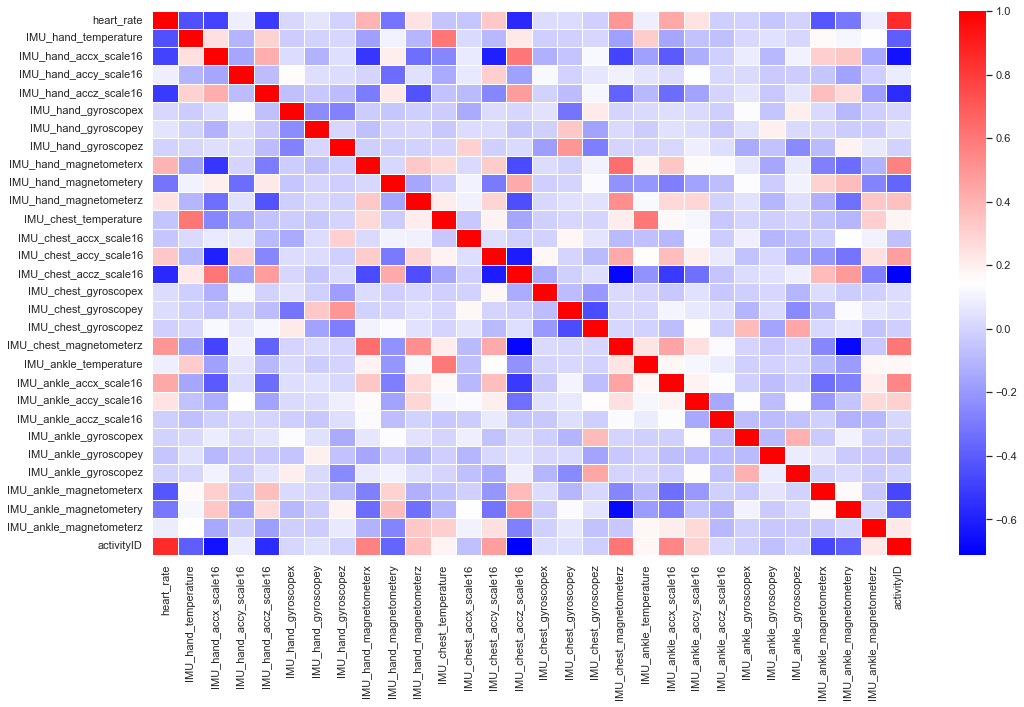

In [27]:
corr = datasets_train.corr()
# the heat map of the corrlations Better visualization
sns.set(rc={'figure.figsize': (17, 10)})
dataplot = sns.heatmap(corr, cmap="bwr", linewidths=.5)

## feature selection using SelectKBest:

##### from the below dataframe we see that the best 4 feature is:

- heart rate 
- IMU chest accelerometer in z direction 
- IMU hand accelerometer in x direction
- IMU hand_magnetometer in x direction


##### `so we can put our model in smart watch and the accuracy will n't be that bad` 

In [28]:
data_x=datasets_train.iloc[:,:-2]
data_y=datasets_train.iloc[:,-1]

fit_feature = SelectKBest()
fit_feature.fit(data_x, data_y)
score_col = pd.DataFrame(fit_feature.scores_, columns=['score_value'])
name_col = pd.DataFrame(data_x.columns,columns=['feature_name'])
top_feature = pd.concat([name_col, score_col], axis=1).nlargest( 31,'score_value')


top_feature['score_value']=top_feature['score_value']/top_feature['score_value'].sum()

top_feature

,feature_name,score_value
0,heart_rate,0.375794
14,IMU_chest_accz_scale16,0.145659
2,IMU_hand_accx_scale16,0.073358
8,IMU_hand_magnetometerx,0.061212
18,IMU_chest_magnetometerz,0.051328
13,IMU_chest_accy_scale16,0.043507
20,IMU_ankle_accx_scale16,0.040198
11,IMU_chest_temperature,0.037406
4,IMU_hand_accz_scale16,0.032929
9,IMU_hand_magnetometery,0.023353


In [29]:
best_feature_name=np.array(top_feature.iloc[:16,0])
best_feature_name

array(['heart_rate', 'IMU_chest_accz_scale16', 'IMU_hand_accx_scale16',
       'IMU_hand_magnetometerx', 'IMU_chest_magnetometerz',
       'IMU_chest_accy_scale16', 'IMU_ankle_accx_scale16',
       'IMU_chest_temperature', 'IMU_hand_accz_scale16',
       'IMU_hand_magnetometery', 'IMU_ankle_magnetometerx',
       'IMU_hand_temperature', 'IMU_ankle_magnetometerz',
       'IMU_ankle_magnetometery', 'IMU_hand_magnetometerz',
       'IMU_ankle_accy_scale16'], dtype=object)

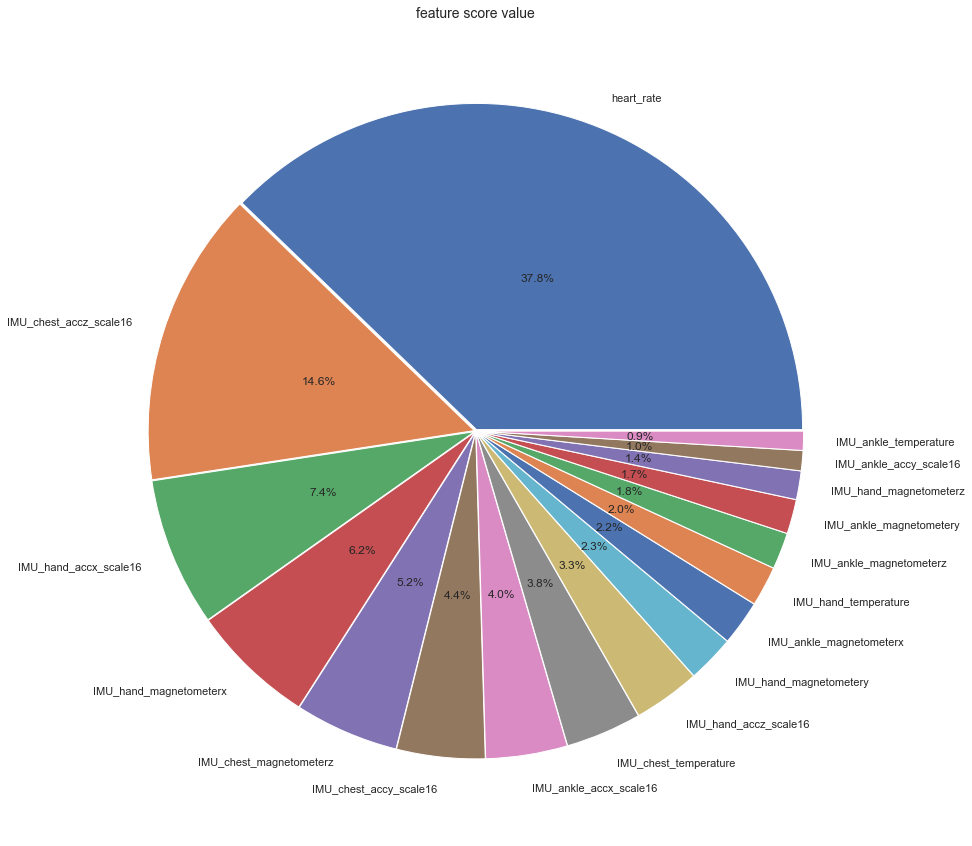

In [30]:
pie, ax = plt.subplots(figsize=[15,15])
plt.pie(x=top_feature.iloc[:17,1], autopct="%.1f%%", explode=[0.005]*len(top_feature.iloc[:17,1]), labels=top_feature.iloc[:17,0], pctdistance=0.5)
plt.title("feature score value", fontsize=14);

plt.show()

### the classes in the data is imbalanced

In Machine Learning and Data Science we often come across a term called Imbalanced Data Distribution, generally happens when observations in one of the class are much higher or lower than the other classes. As Machine Learning algorithms tend to increase accuracy by reducing the error, they do not consider the class distribution. This problem is prevalent in examples such as Fraud Detection, Anomaly Detection, Facial recognition etc.

Standard ML techniques such as Decision Tree and Logistic Regression have a bias towards the majority class, and they tend to ignore the minority class. They tend only to predict the majority class, hence, having major misclassification of the minority class in comparison with the majority class. In more technical words, if we have imbalanced data distribution in our dataset then our model becomes more prone to the case when minority class has negligible or very lesser recall.

Imbalanced Data Handling Techniques: There are mainly 2 mainly algorithms that are widely used for handling imbalanced class distribution.

- SMOTE
- Near Miss Algorithm


- `i will do undersampling manualy as the data describe the population well`

https://www.geeksforgeeks.org/ml-handling-imbalanced-data-with-smote-and-near-miss-algorithm-in-python/

In [31]:
index0=[]

walking_indx=datasets_train[datasets_train['activityID']==4].index
index0.append(walking_indx[walking_indx<345000])

sitting_indx=datasets_train[datasets_train['activityID']==2].index
index0.append(sitting_indx[sitting_indx<240000])

laying_indx=datasets_train[datasets_train['activityID']==1].index
index0.append(laying_indx[laying_indx<228000])

# for i in index0:
#     print(i.shape)

balanced_datasets_train=datasets_train.copy()


for i in range(3):

    balanced_datasets_train.drop(datasets_train.loc[index0[i],:].index,axis=0,inplace=True)

#--------------------------------------------------------------------------
index1=[]

walking_indx=datasets_test[datasets_test['activityID']==4].index
index1.append(walking_indx[walking_indx<105000])

sitting_indx=datasets_test[datasets_test['activityID']==2].index
index1.append(sitting_indx[sitting_indx<79000])

laying_indx=datasets_test[datasets_test['activityID']==1].index
index1.append(laying_indx[laying_indx<75000])

# for i in index1:
#     print(i.shape)

balanced_datasets_test=datasets_test.copy()


for i in range(3):

    balanced_datasets_test.drop(datasets_test.loc[index1[i],:].index,axis=0,inplace=True)



#### visualize the data after balancing :

Text(0.5, 0, 'balanced_datasets_test')

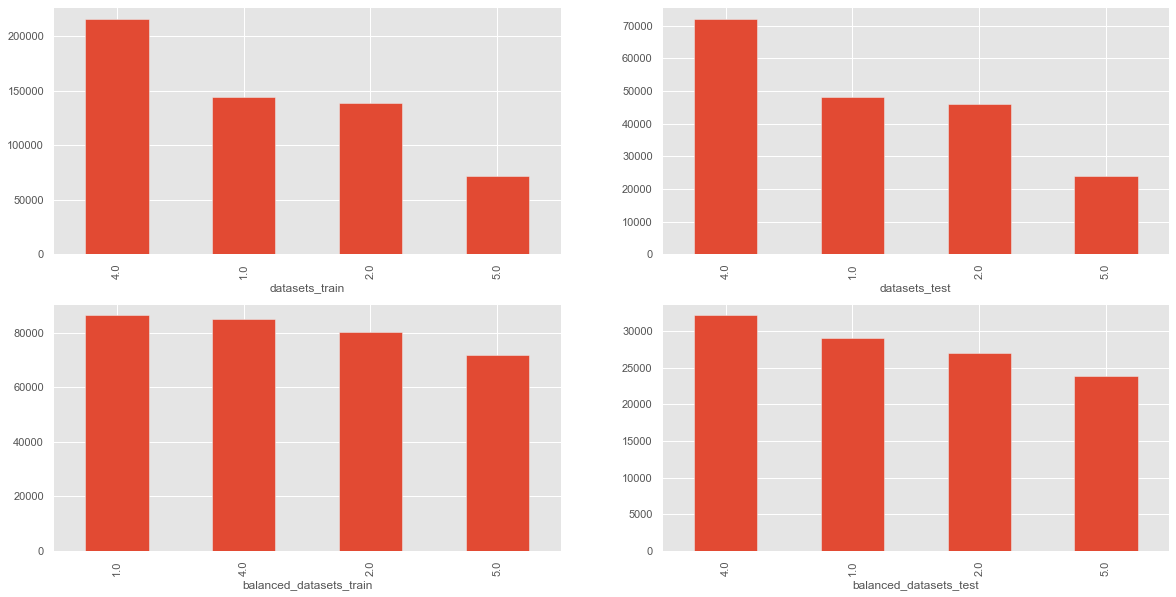

In [32]:
# plt.rcParams["figure.figsize"] = (10,10)
plt.style.use('ggplot')
fig, axes = plt.subplots(2,2, figsize=(20, 10))

datasets_train['activityID'].value_counts().plot(ax=axes[0,0], kind='bar', grid=True)
datasets_test['activityID'].value_counts().plot(ax=axes[0,1], kind='bar', grid=True)
balanced_datasets_train['activityID'].value_counts().plot(ax=axes[1,0], kind='bar', grid=True)
balanced_datasets_test['activityID'].value_counts().plot(ax=axes[1,1], kind='bar', grid=True)
#------------------------------------------------------------------------
axes[0,0].set_xlabel('datasets_train')
axes[0,1].set_xlabel('datasets_test')
axes[1,0].set_xlabel('balanced_datasets_train')
axes[1,1].set_xlabel('balanced_datasets_test')

In [33]:
print('datasets_train:',datasets_train.shape[0],'            datasets_test:',datasets_test.shape[0],'           percentage:',datasets_test.shape[0]/datasets_train.shape[0])
print('balanced_datasets_train:',balanced_datasets_train.shape[0],'   balanced_datasets_test:',balanced_datasets_test.shape[0],'    percentage:',balanced_datasets_test.shape[0]/balanced_datasets_train.shape[0])


datasets_train: 570399             datasets_test: 190208            percentage: 0.3334648202398672
balanced_datasets_train: 323380    balanced_datasets_test: 112086     percentage: 0.3466077061042736


### visualizing the subjects ratio before and after the balancing:

Text(0.5, 0, 'balanced_datasets_test')

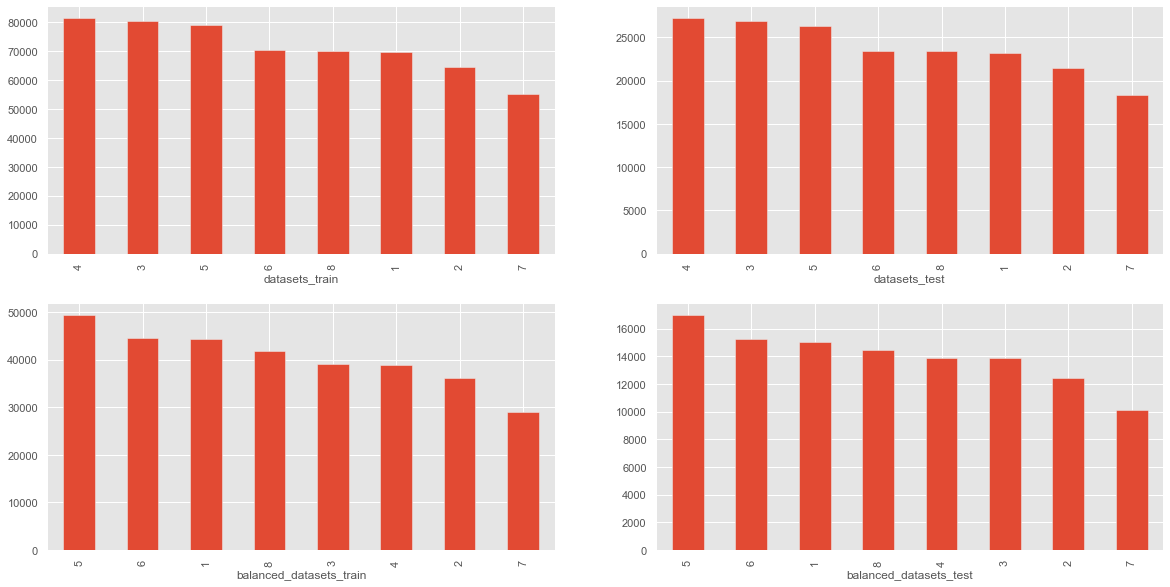

In [34]:
plt.style.use('ggplot')
fig, axes = plt.subplots(2,2, figsize=(20, 10))

datasets_train['person'].value_counts().plot(ax=axes[0,0], kind='bar', grid=True)
datasets_test['person'].value_counts().plot(ax=axes[0,1], kind='bar', grid=True)
balanced_datasets_train['person'].value_counts().plot(ax=axes[1,0], kind='bar', grid=True)
balanced_datasets_test['person'].value_counts().plot(ax=axes[1,1], kind='bar', grid=True)
#------------------------------------------------------------------------
axes[0,0].set_xlabel('datasets_train')
axes[0,1].set_xlabel('datasets_test')
axes[1,0].set_xlabel('balanced_datasets_train')
axes[1,1].set_xlabel('balanced_datasets_test')

### shuffling the balanced data to generlize it more

In [35]:
for i in range(200):

    balanced_datasets_train=shuffle(balanced_datasets_train,random_state=100)
    balanced_datasets_test=shuffle(balanced_datasets_test,random_state=100)

#### here we are making mini version which is representing the data to help speeding the model

In [36]:
mini_datasets_train=balanced_datasets_train.iloc[5000:15000,:]
# mini_datasets_train.drop(balanced_datasets_train.loc[balanced_datasets_train.index<315000].index,axis=0,inplace=True)
mini_datasets_test=balanced_datasets_test.iloc[2000:5300,:]
# mini_datasets_test.drop(balanced_datasets_test.loc[balanced_datasets_test.index<116000].index,axis=0,inplace=True)

### in the below to block we visualising the mini data and to check if it's indeed representing the data

Text(0.5, 0, 'mini_datasets_test')

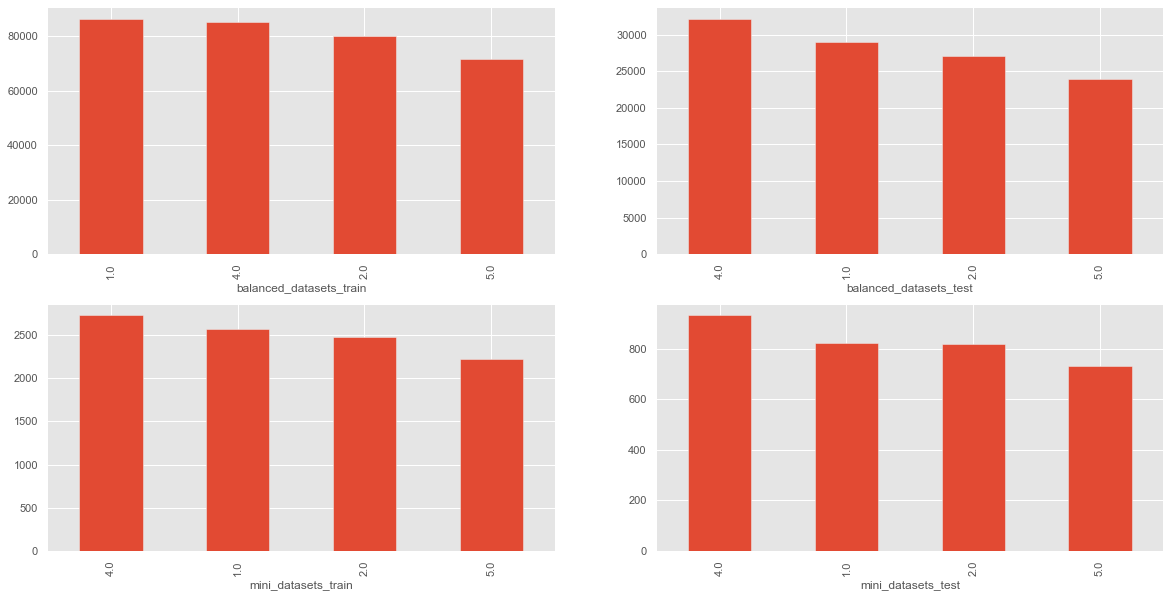

In [37]:
# plt.rcParams["figure.figsize"] = (10,10)
plt.style.use('ggplot')
fig, axes = plt.subplots(2,2, figsize=(20, 10))

balanced_datasets_train['activityID'].value_counts().plot(ax=axes[0,0], kind='bar', grid=True)
balanced_datasets_test['activityID'].value_counts().plot(ax=axes[0,1], kind='bar', grid=True)
mini_datasets_train['activityID'].value_counts().plot(ax=axes[1,0], kind='bar', grid=True)
mini_datasets_test['activityID'].value_counts().plot(ax=axes[1,1], kind='bar', grid=True)
#------------------------------------------------------------------------
axes[0,0].set_xlabel('balanced_datasets_train')
axes[0,1].set_xlabel('balanced_datasets_test')
axes[1,0].set_xlabel('mini_datasets_train')
axes[1,1].set_xlabel('mini_datasets_test')

Text(0.5, 0, 'mini_datasets_test')

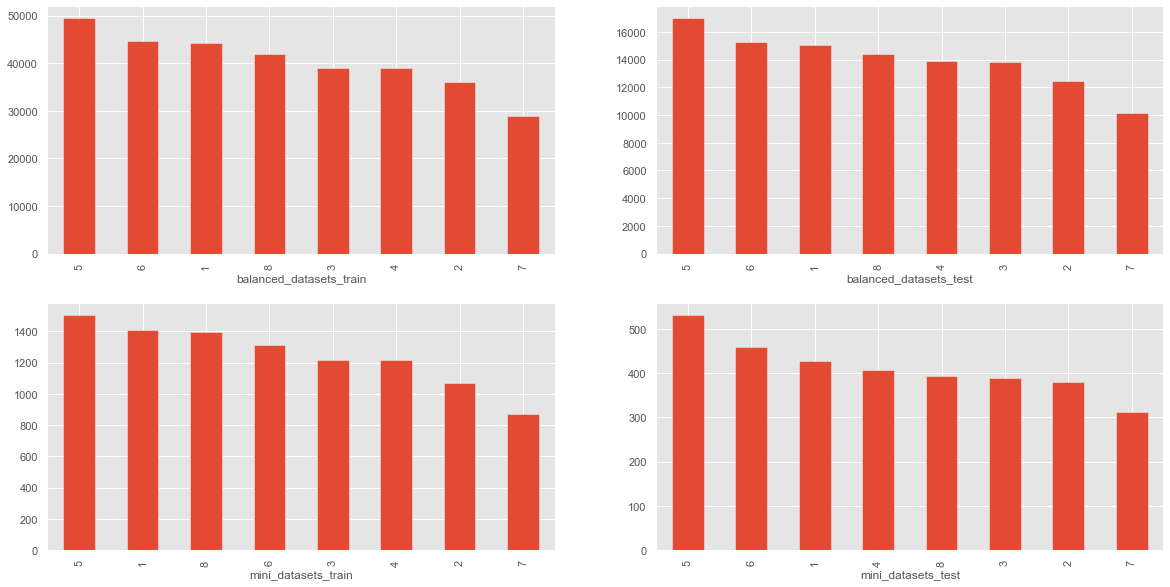

In [38]:
plt.style.use('ggplot')
fig, axes = plt.subplots(2,2, figsize=(20, 10))

balanced_datasets_train['person'].value_counts().plot(ax=axes[0,0], kind='bar', grid=True)
balanced_datasets_test['person'].value_counts().plot(ax=axes[0,1], kind='bar', grid=True)
mini_datasets_train['person'].value_counts().plot(ax=axes[1,0], kind='bar', grid=True)
mini_datasets_test['person'].value_counts().plot(ax=axes[1,1], kind='bar', grid=True)
#------------------------------------------------------------------------
axes[0,0].set_xlabel('balanced_datasets_train')
axes[0,1].set_xlabel('balanced_datasets_test')
axes[1,0].set_xlabel('mini_datasets_train')
axes[1,1].set_xlabel('mini_datasets_test')

In [39]:
balanced_data_y=balanced_datasets_train.iloc[:,-1]
balanced_data_x=balanced_datasets_train.iloc[:,:-2]
data_y=datasets_train.iloc[:,-1]
data_x=datasets_train.iloc[:,:-2]
mini_data_y=mini_datasets_train.iloc[:,-1]
mini_data_x=mini_datasets_train.iloc[:,:-2]

In [40]:

pca = PCA(n_components = 2)
PCA_X_train = pca.fit_transform(data_x)
PCA_balanced_X_train = pca.fit_transform(balanced_data_x)
PCA_mini_X_train = pca.fit_transform(mini_data_x)

#### from the below scatter plot we vasulize the data in scatter plot  before and after the balancing and PCA:

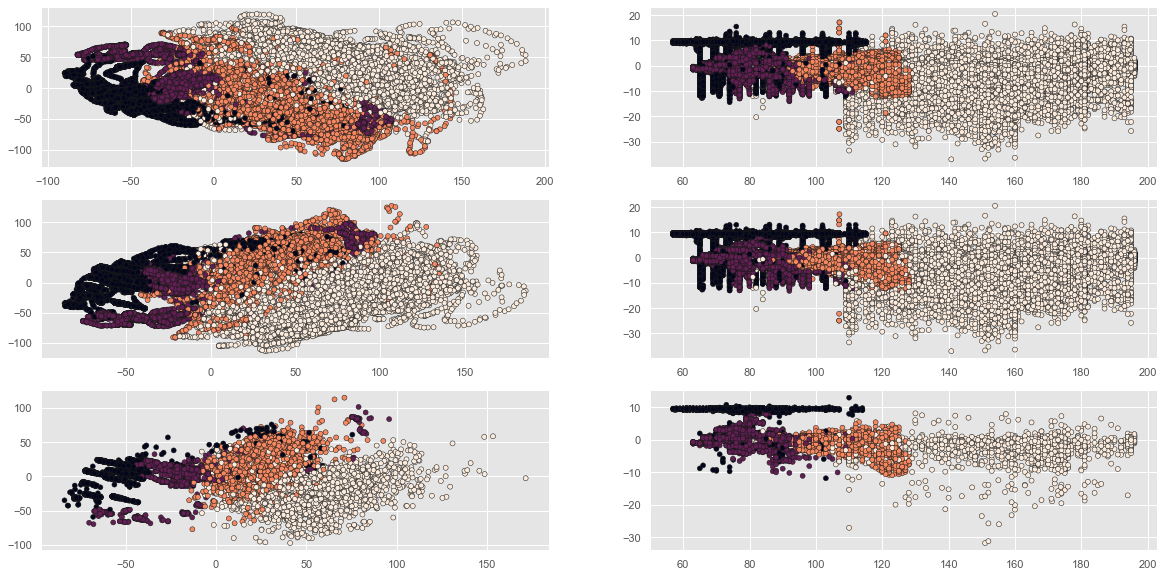

In [41]:
# plt.rcParams["figure.figsize"] = (10,10)

fig, subaxes = plt.subplots(3,2, figsize=(20, 10))

subaxes[0,0].scatter(PCA_X_train[:,0], PCA_X_train[:,1], marker="o", c=data_y, s=25, edgecolor="k")
subaxes[0,1].scatter(datasets_train['heart_rate'], datasets_train['IMU_chest_accz_scale16'], marker="o", c=datasets_train['activityID'], s=25, edgecolor="k")
subaxes[1,0].scatter(PCA_balanced_X_train[:,0], PCA_balanced_X_train[:,1], marker="o", c=balanced_data_y, s=25, edgecolor="k")
subaxes[1,1].scatter(balanced_datasets_train['heart_rate'],balanced_datasets_train['IMU_chest_accz_scale16'], marker="o", c=balanced_datasets_train['activityID'], s=25, edgecolor="k")
subaxes[2,0].scatter(PCA_mini_X_train[:,0], PCA_mini_X_train[:,1], marker="o", c=mini_data_y, s=25, edgecolor="k")
subaxes[2,1].scatter(mini_datasets_train['heart_rate'],mini_datasets_train['IMU_chest_accz_scale16'], marker="o", c=mini_datasets_train['activityID'], s=25, edgecolor="k")
#------------------------------------------------------------------------
# axes[0,0].set_xlabel('datasets_train')
# axes[0,1].set_xlabel('datasets_test')
# axes[1,0].set_xlabel('balanced_datasets_train')
# axes[1,1].set_xlabel('balanced_datasets_test')
# axes[2,0].set_xlabel('mini_datasets_train')
# axes[2,1].set_xlabel('mini_datasets_test')


##### -----------------------------------------------------------------------------------------------------------------------------------------

#### final preprocessing step naming the dataframe 

In [42]:
# (1)
X_train = datasets_train[best_feature_name]
y_train = datasets_train['activityID']
X_test = datasets_test[best_feature_name]
y_test = datasets_test['activityID']
# ----------------------------------------
# (2)
balanced_X_train = balanced_datasets_train[best_feature_name]
balanced_y_train = balanced_datasets_train['activityID']
balanced_X_test = balanced_datasets_test[best_feature_name]
balanced_y_test = balanced_datasets_test['activityID']
# -----------------------------------------
# (3)
scaled_X_train = StandardScaler().fit_transform(balanced_X_train)
scaled_y_train = balanced_y_train
scaled_X_test = StandardScaler().fit_transform(balanced_X_test)
scaled_y_test = balanced_y_test
# -------------------------------------------
# (4)
normalize_X_train = normalize(balanced_X_train)
normalize_y_train = balanced_y_train
normalize_X_test = normalize(balanced_X_test)
normalize_y_test = balanced_y_test
# --------------------------------------------
# (5)
#PCA_X_train = PCA(n_components=10).fit_transform(balanced_X_train)
#PCA_y_train = balanced_y_train
#PCA_X_test = PCA(n_components=10).fit_transform(balanced_X_test)
#PCA_y_test = balanced_y_test
# ----------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------
# (6)
mini_X_train = mini_datasets_train[best_feature_name]
mini_y_train = mini_datasets_train['activityID']
mini_X_test = mini_datasets_test[best_feature_name]
mini_y_test = mini_datasets_test['activityID']
# -------------------------------------------
# (7)
mini_scaled_X_train = StandardScaler().fit_transform(mini_X_train)
mini_scaled_y_train = mini_y_train
mini_scaled_X_test = StandardScaler().fit_transform(mini_X_test)
mini_scaled_y_test = mini_y_test
# -------------------------------------------
# (8)
mini_normalize_X_train = normalize(mini_X_train)
mini_normalize_y_train = mini_y_train
mini_normalize_X_test = normalize(mini_X_test)
mini_normalize_y_test = mini_y_test
# --------------------------------------------
# (9)
#mini_PCA_X_train = PCA(n_components=10).fit_transform(mini_X_train)
#mini_PCA_y_train = mini_y_train
#mini_PCA_X_test = PCA(n_components=10).fit_transform(mini_X_test)
#mini_PCA_y_test = mini_y_test


#### **Getting red of unwanted warnings**

In [ ]:
import warnings
warnings.filterwarnings('ignore')
warnings.warn('DelftStack')
warnings.warn('Do not show this message')

## **Saving proccessed data to CSV files, to save running time**

In [ ]:
###########################################################################################
# saving the Origional data, where features & classes were reduced into a csv file
##########################################################################################

# traing_data csv file
Pre_processing_train_data = X_train
Pre_processing_train_data['activityID'] = y_train
Pre_processing_train_data.head()

Pre_processing_train_data.to_csv(
    'data_CSV\Pre_processing_train_data.csv', index=False)

# testing_data csv file
Pre_processing_test_data = X_test
Pre_processing_test_data['activityID'] = y_test
Pre_processing_test_data.head()

Pre_processing_test_data.to_csv(
    'data_CSV\Pre_processing_test_data.csv', index=False)


In [ ]:

###################################################################################
# saving Balanced data, the Orgional data after balancing into a csv file
###################################################################################

# traing_data csv file
post_processing_train_data = balanced_X_train
post_processing_train_data['activityID'] = balanced_y_train
post_processing_train_data.head()

post_processing_train_data.to_csv(
    'data_CSV\post_processing_train_data.csv', index=False)

# testing_data csv file
post_processing_test_data = balanced_X_test
post_processing_test_data['activityID'] = balanced_y_test
post_processing_test_data.head()

post_processing_test_data.to_csv(
    'data_CSV\post_processing_test_data.csv', index=False)


In [ ]:
#################################################################################################
# saving mini data, a small sample of balanced data that has the same propotions into svs file
################################################################################################

# traing_data csv file
mini_train_data = mini_X_train
mini_train_data['activityID'] = mini_data_y
mini_train_data.head()

mini_train_data.to_csv('data_CSV\mini_train_data.csv', index=False)

# testing_data csv file
mini_test_data = mini_X_test
mini_test_data['activityID'] = mini_y_test
mini_test_data.head()

mini_test_data.to_csv('data_CSV\mini_test_data.csv', index=False)
